# Web APIs 第四天：日期对象、DOM 节点与移动端交互

## 0. 本课内容与资料

本课对应 JavaScript 第 09 篇。按讲义顺序学习：日期对象 → 节点操作 → M 端事件 → JavaScript 插件 → 游乐园轮播图与学生信息表，最后理解浏览器的重绘和回流。

学习目标是能利用节点的查找、创建、插入和删除完成页面操作，并把表单数据保存到数组中，再根据数组渲染学生信息表。

主资料来自[用户提供的百度网盘分享](https://pan.baidu.com/s/1MxueOHXGQtmE-ypRq1kELA?pwd=9987)，提取码 `9987`，位置为 `2.web APIs / 资料 / web APIs 第四天`。已逐页读取 `01-PPT/web APIs第四天.pdf` 的全部 54 页公开预览；本篇教学图裁自该讲义并内嵌保存。

练习代码使用[同课公开练习副本](https://github.com/wukaihang/pink-javascript/tree/main/2.Web%20APIs/day4)。下文标为“公开副本原代码”的内容保留原缩进、变量、注释及启用状态；讲义转录、整理示例和局部修正分别注明。网盘原 Markdown、原课堂源码、测试题及作业正文尚未取得，未把公开副本当成这些文件的原文。

## 1. 日期对象

页面要显示当前时间、指定日期或倒计时，先通过 `Date` 得到日期对象，再调用方法提取需要的部分。日期对象是 JavaScript 内置对象。

### 1.1 实例化：当前时间与指定时间

在 `01-实例化日期对象.html` 中，`new Date()` 不传参数时得到创建对象这一刻的系统时间；传入日期参数时得到指定时间。讲义用 `new Date('2008-8-8')` 演示指定日期，公开副本使用下面的日期。

公开副本原脚本：

```javascript
    // 实例化日期对象 new
    // 1. 不传参数，默认得到当前时间
    const date = new Date()
    console.log(date)
    // 2. 传参数，得到指定时间
    const date1 = new Date('2023-03-01 12:00:00')
    console.log(date1)
  
```

打开页面看控制台：第一个对象是当前时间，第二个对象是指定的 2023 年 3 月 1 日 12 点。`Date` 对象不会随着时间自动更新；实时显示需要重新创建对象。

> 日期字符串的解析要留意格式。原例中的空格日期格式在不同浏览器中可能有差异；需要明确的本地时间时，可以用 `new Date(2023, 2, 1, 12, 0, 0)`，这里的月份参数 `2` 表示三月。原代码保留不改。

### 1.2 取得年月日、星期和时分秒

日期对象的方法把时间拆成不同部分。讲义方法表：

| 方法 | 含义 | 返回值要点 |
| --- | --- | --- |
| `getFullYear()` | 年 | 四位年份 |
| `getMonth()` | 月 | `0～11`，显示月份要加 `1` |
| `getDate()` | 日 | 当月第几天，`1～31` |
| `getDay()` | 星期 | `0～6`，`0` 是星期日，`6` 是星期六 |
| `getHours()` | 时 | `0～23` |
| `getMinutes()` | 分 | `0～59` |
| `getSeconds()` | 秒 | `0～59` |

`02-常见的日期对象方法.html` 公开副本原脚本：

```javascript
    // 实例化日期对象
    // 1. 得到当前时间
    const date = new Date()
    console.log(date)
    // 2. 使用Date对象的方法，得到日期的不同部分
    console.log(date.getFullYear())
    console.log(date.getMonth())
    console.log(date.getDate())
    console.log(date.getDay()) // 星期几 0-6 0表示星期日
    console.log(date.getHours())
    console.log(date.getMinutes())
    console.log(date.getSeconds()) 
  
```

控制台中的月份比日常月份小 `1`，这是方法规定，并非系统时间错误。`getDate()` 取日期，`getDay()` 取星期，两者不能混用。

### 1.3 页面显示格式化时间

讲义要求显示 `YYYY-MM-DD HH:mm`，例如 `2008-08-08 08:08`。做法是取出各部分，给不足两位的数字补 `0`，拼成字符串，再写入页面。

公开副本 `03-显示格式化的时间.html` 展示的是中文年月日和时分秒，完整原代码：

```html
<!DOCTYPE html>
<html lang="zh-CN">

<head>
  <meta charset="UTF-8">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>

<body>
  <div></div>
  <script>
    const div = document.querySelector('div')
    function getMyDate() {
      const date = new Date()
      let h = date.getHours()
      let m = date.getMinutes()
      let s = date.getSeconds()
      h = h < 10 ? '0' + h : h
      m = m < 10 ? '0' + m : m
      s = s < 10 ? '0' + s : s
      return `今天是${date.getFullYear()}年${date.getMonth() + 1}月${date.getDate()}日 ${h}时${m}分${s}秒`
    }
    setInterval(() => {
      div.innerHTML = getMyDate()
    }, 1000)
  </script>
</body>

</html>
```

`getMyDate()` 返回字符串，定时器每秒重新读取时间并更新 `div`。原例只给时、分、秒补零，月份和日期不补零；页面刚打开时 `div` 为空，要等第一次定时回调才显示。若希望立即显示，可在开启定时器前加 `div.innerHTML = getMyDate()`。

下面是**按讲义显示格式整理的示例**，另存为一个 HTML 页面使用。它与上面的中文日期版本是两种展示格式。

```html
<!DOCTYPE html>
<html lang="zh-CN">
<head>
  <meta charset="UTF-8">
  <title>格式化当前时间</title>
</head>
<body>
  <div class="time"></div>
  <script>
    const time = document.querySelector('.time')
    function pad(num) {
      return num < 10 ? '0' + num : num
    }
    function showTime() {
      const date = new Date()
      time.innerText = `${date.getFullYear()}-${pad(date.getMonth() + 1)}-${pad(date.getDate())} ${pad(date.getHours())}:${pad(date.getMinutes())}`
    }
    showTime()
    setInterval(showTime, 1000)
  </script>
</body>
</html>
```

打开页面应立即看到年月日和时分，月、日、时、分始终是两位。

### 1.4 时间的另一种写法

`04-时间的另一个写法.html` 使用 `toLocaleString()`。页面放一个 `div`，原脚本如下：

```javascript
    const div = document.querySelector('div')
    const date = new Date()
    div.innerHTML = date.toLocaleString()
    setInterval(() => {
      const date = new Date()
      div.innerHTML = date.toLocaleString()
    }, 1000)
  
```

它先显示一次，再每秒更新。`toLocaleString()` 按运行环境的地区设置产生日期时间字符串，具体分隔符、日期顺序及 12/24 小时制可能不同；要求固定格式时使用上一节的拼接方式。

### 1.5 时间戳：把时间转换为毫秒数

时间戳表示从 `1970-01-01T00:00:00Z` 到目标时间经过的毫秒数。未来时间戳减去当前时间戳得到剩余毫秒，除以 `1000` 得到剩余秒数，便于计算倒计时。

| 写法 | 当前时间 | 指定时间 |
| --- | --- | --- |
| `date.getTime()` | 先创建当前日期对象 | 对指定日期对象调用 |
| `+new Date()` | 不传参数 | 给 `Date` 传入指定日期 |
| `Date.now()` | 直接获得当前时间戳 | 此方法不用于指定日期 |

`05-得到时间戳.html` 公开副本原脚本：

```javascript
    // 1. getTime()
    const date = new Date()
    console.log(date.getTime())
    // 2. +new Date() 常用
    console.log(+new Date())
    // 3. Date.now()
    console.log(Date.now())

    // 得到指定时间的时间戳
    console.log(new Date('2023-01-01 18:30:00').getTime())

    // 根据 Day() 返回星期几
    const arr = ['星期日', '星期一', '星期二', '星期三', '星期四', '星期五', '星期六']
    console.log(arr[new Date().getDay()])
  
```

三种当前时间戳写法得到的数值应相同或非常接近；连续调用跨过一个毫秒时会略有差别。讲义重点要求记住 `+new Date()`。

原注释写“根据 Day()”，实际调用的是 `getDay()`。星期数组从星期日开始，正好用 `getDay()` 的返回值作索引。

### 1.6 倒计时：剩余秒数转换为天、时、分、秒

讲义以毕业、下课等倒计时说明需求，界面示例标题为“下班倒计时”。

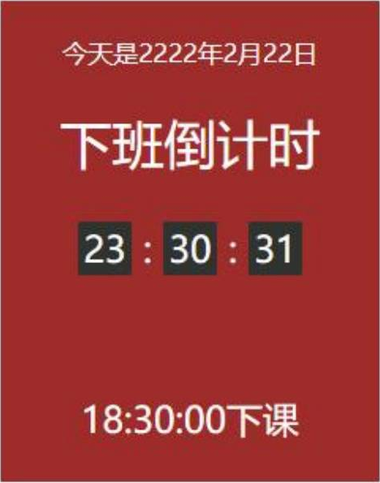

先算 `总秒数 = (未来时间戳 - 当前时间戳) / 1000`，再按讲义公式拆分。以下为**讲义公式转录**，变量 `count` 表示剩余总秒数：

```javascript
let d = parseInt(count / 60 / 60 / 24)
let h = parseInt(count / 60 / 60 % 24)
let m = parseInt(count / 60 % 60)
let s = parseInt(count % 60)
```

`% 24` 留下不足一天的小时，`% 60` 留下不足一小时的分钟或不足一分钟的秒。倒计时跨越多天时，要同时显示 `d`，否则小时不能表示全部剩余时间。

`06-倒计时.html` 公开副本完整原代码：

```html
<!DOCTYPE html>
<html lang="en">

<head>
  <meta charset="UTF-8" />
  <meta http-equiv="X-UA-Compatible" content="IE=edge" />
  <meta name="viewport" content="width=device-width, initial-scale=1.0" />
  <title>Document</title>
  <style>
    .countdown {
      width: 240px;
      height: 305px;
      text-align: center;
      line-height: 1;
      color: #fff;
      background-color: brown;
      /* background-size: 240px; */
      /* float: left; */
      overflow: hidden;
    }

    .countdown .next {
      font-size: 16px;
      margin: 25px 0 14px;
    }

    .countdown .title {
      font-size: 33px;
    }

    .countdown .tips {
      margin-top: 80px;
      font-size: 23px;
    }

    .countdown small {
      font-size: 17px;
    }

    .countdown .clock {
      width: 142px;
      margin: 18px auto 0;
      overflow: hidden;
    }

    .countdown .clock span,
    .countdown .clock i {
      display: block;
      text-align: center;
      line-height: 34px;
      font-size: 23px;
      float: left;
    }

    .countdown .clock span {
      width: 34px;
      height: 34px;
      border-radius: 2px;
      background-color: #303430;
    }

    .countdown .clock i {
      width: 20px;
      font-style: normal;
    }
  </style>
</head>

<body>
  <div class="countdown">
    <p class="next">今天是2025年11月12日</p>
    <p class="title">下班倒计时</p>
    <p class="clock">
      <span id="hour">00</span>
      <i>:</i>
      <span id="minutes">25</span>
      <i>:</i>
      <span id="scond">20</span>
    </p>
    <p class="tips">18:30:00下课</p>
  </div>
  <script>
    // 随机颜色函数
    // 1. 自定义一个随机颜色函数
    function getRandomColor(flag = true) {
      if (flag) {
        // 3. 如果是true 则返回 #ffffff
        let str = '#'
        let arr = ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', 'a', 'b', 'c', 'd', 'e', 'f']
        // 利用for循环随机抽6次 累加到 str里面
        for (let i = 1; i <= 6; i++) {
          // 每次要随机从数组里面抽取一个  
          // random 是数组的索引号 是随机的
          let random = Math.floor(Math.random() * arr.length)
          // str = str + arr[random]
          str += arr[random]
        }
        return str

      } else {
        // 4. 否则是 false 则返回 rgb(255,255,255)
        let r = Math.floor(Math.random() * 256)  // 55
        let g = Math.floor(Math.random() * 256)  // 89
        let b = Math.floor(Math.random() * 256)  // 255
        return `rgb(${r},${g},${b})`
      }

    }

    // 页面刷新随机得到颜色
    const countdown = document.querySelector('.countdown')
    countdown.style.backgroundColor = getRandomColor()
    // 函数封装 getCountTime
    function getCountTime() {
      // 1. 得到当前的时间戳
      const now = +new Date()
      // 2. 得到将来的时间戳
      const last = +new Date('2025-11-12 18:30:00')
      // console.log(now, last)
      // 3. 得到剩余的时间戳 count  记得转换为 秒数
      const count = (last - now) / 1000
      // console.log(count)
      // 4. 转换为时分秒
      // h = parseInt(总秒数 / 60 / 60 % 24)   //   计算小时
      // m = parseInt(总秒数 / 60 % 60);     //   计算分数
      // s = parseInt(总秒数 % 60);   
      // let d = parseInt(count / 60 / 60 / 24)               //   计算当前秒数
      let h = parseInt(count / 60 / 60 % 24)
      h = h < 10 ? '0' + h : h
      let m = parseInt(count / 60 % 60)
      m = m < 10 ? '0' + m : m
      let s = parseInt(count % 60)
      s = s < 10 ? '0' + s : s
      console.log(h, m, s)

      //  5. 把时分秒写到对应的盒子里面
      document.querySelector('#hour').innerHTML = h
      document.querySelector('#minutes').innerHTML = m
      document.querySelector('#scond').innerHTML = s
    }
    // 先调用一次
    getCountTime()

    // 开启定时器
    setInterval(getCountTime, 1000)
  </script>
</body>

</html>
```

打开页面时先调用一次 `getCountTime()`，然后每秒更新；每次都重新计算未来时间与当前时间的差。随机颜色函数用于页面刷新时更换背景，核心倒计时从 `getCountTime()` 开始。

> 原例目标为 `2025-11-12 18:30:00`，在本篇整理日 `2026-10-13` 已过期。直接运行会出现负值及不合适的补零效果。练习时需同时替换脚本目标时间与页面日期、结束时间文案，不能只改其中一处。

为到期后显示 `00:00:00`，可把原来的 `count` 定义替换为下面这一行，属于**局部修正**：

```javascript
const count = Math.max(0, Math.floor((last - now) / 1000))
```

原代码注释中 `d` 的计算被写成“计算当前秒数”，实际是计算天数。秒数盒子的原 ID 是 `scond`，虽然拼写不标准，但 HTML 与选择器一致；只改一侧会找不到元素。

## 2. 节点操作

前面通过选择器查找元素，本节进一步利用 DOM 中的父、子、兄弟关系查找元素，并通过创建、插入、克隆、删除改变页面结构。

### 2.1 DOM 节点与树结构

DOM 树中的内容都有对应的节点。讲义主要介绍元素节点、属性节点和文本节点，本课重点操作元素节点，例如 `html`、`body`、`div`。

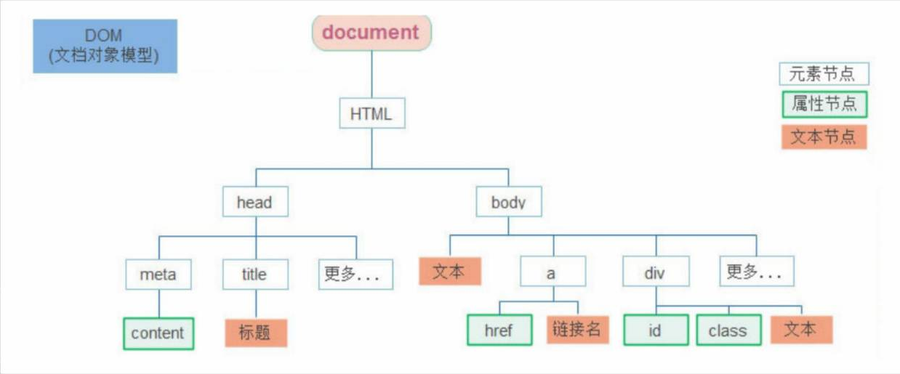

`html` 是根元素，整个文档的根节点是 `document`。`href`、`class` 等属于元素的属性，不是该元素的 `children` 子节点；标签中的文字属于文本节点。

### 2.2 父节点：从当前元素找到容器

例如关闭二维码或广告，点击的是内部按钮，要隐藏的是按钮所在的整个盒子。此时不用再查一次容器，直接取按钮的父节点。

语法是 `子元素.parentNode`，返回最近的父节点，没有父节点时返回 `null`。

`07-父节点.html` 公开副本完整原代码：

```html
<!DOCTYPE html>
<html lang="zh-CN">

<head>
  <meta charset="UTF-8">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>

<body>
  <div class="grandpa">
    <div class="dad">
      <div class="baby"></div>
    </div>
  </div>

  <script>
    const baby = document.querySelector('.baby')
    console.log(baby)
    console.log(baby.parentNode)
    console.log(baby.parentNode.parentNode)
  </script>
</body>

</html>
```

`.baby.parentNode` 是 `.dad`，再取一次 `parentNode` 得到 `.grandpa`。每次取的是相邻的一层父节点。

### 2.3 点击关闭：只隐藏当前按钮的父盒子

讲义使用二维码关闭案例说明父节点的用途。公开副本 `08-点击关闭.html` 用三个广告盒子演示相同关系。下面摘录其原 HTML 和样式；文件开头的聊天时间文字不是教学代码，省略。

```html
  <div class="box">
    我是广告
    <div class="box1">X</div>
  </div>
  <div class="box">
    我是广告
    <div class="box1">X</div>
  </div>
  <div class="box">
    我是广告
    <div class="box1">X</div>
  </div>
```

```css
    .box {
      position: relative;
      width: 1000px;
      height: 200px;
      background-color: pink;
      margin: 100px auto;
      text-align: center;
      font-size: 50px;
      line-height: 200px;
      font-weight: 700;
    }

    .box1 {
      position: absolute;
      right: 20px;
      top: 10px;
      width: 20px;
      height: 20px;
      background-color: skyblue;
      text-align: center;
      line-height: 20px;
      font-size: 16px;
      cursor: pointer;
    }
  
```

公开副本原脚本：

```javascript
    // // 1. 获取事件源
    // const box1 = document.querySelector('.box1')
    // // 2. 事件侦听
    // box1.addEventListener('click', function () {
    //   this.parentNode.style.display = 'none'
    // })

    // 1. 获取三个关闭按钮
    const closeBtn = document.querySelectorAll('.box1')
    // for (let i = 0; i < closeBtn.length; i++) {
    //   closeBtn[i].addEventListener('click', function () {
    //     // 关闭我的爸爸 所以只关闭当前的父元素
    //     this.parentNode.style.display = 'none'
    //   })
    // }

    closeBtn.forEach(item => {
      item.addEventListener('click', function () {
        this.parentNode.style.display = 'none'
      })
    })
  
```

启用的是 `forEach` 版本，单按钮版本和 `for` 版本仍保持注释。点击某个 `X`，普通函数中的 `this` 指向当前按钮，`this.parentNode` 指向其父盒子，因此另外两个广告继续显示。

这里的操作是设置 `display: none`：元素仍存在于 DOM 中，但不显示，也不占据布局空间。

### 2.4 子节点和相邻兄弟元素

| 属性 | 查找内容 | 注意点 |
| --- | --- | --- |
| `childNodes` | 全部子节点 | 包括文本、注释，HTML 换行空白也可能产生文本节点 |
| `children` | 子元素 | 返回可按索引访问的集合，本课称“伪数组” |
| `previousElementSibling` | 上一个兄弟元素 | 没有时为 `null` |
| `nextElementSibling` | 下一个兄弟元素 | 没有时为 `null` |

`09-子节点.html` 公开副本完整原代码：

```html
<!DOCTYPE html>
<html lang="zh-CN">

<head>
  <meta charset="UTF-8">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>

<body>
  <ul>
    <li>1</li>
    <li>2</li>
    <li>3</li>
    <li>4</li>
    <li>5</li>
  </ul>
  <script>
    const ul = document.querySelector('ul')
    // 1. 子节点
    console.log(ul.children)
    const li2 = document.querySelector('li:nth-child(2)')
    console.log(li2)
    // 2. 上一个兄弟节点
    console.log(li2.previousElementSibling)
    // 3. 下一个兄弟节点
    console.log(li2.nextElementSibling)
  </script>
</body>

</html>
```

控制台的 `ul.children` 包含五个 `li`。第二个 `li` 的前一个兄弟元素内容为 `1`，后一个为 `3`。查找父、子、兄弟都是先获取一个已知元素，再沿树关系定位目标。

### 2.5 创建与插入节点

发布微博、增加列表项等功能需要产生新元素。先创建，再填写内容，最后插入 DOM；只创建而未插入，页面看不到它。

| 方法 | 用途 |
| --- | --- |
| `document.createElement('标签名')` | 创建一个元素节点 |
| `父元素.appendChild(新元素)` | 插到父元素内部的末尾 |
| `父元素.insertBefore(新元素, 参考子元素)` | 插到指定子元素前面 |

`10-增加节点.html` 公开副本完整原代码：

```html
<!DOCTYPE html>
<html lang="zh-CN">

<head>
  <meta charset="UTF-8">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
  <style>
    div {
      width: 100px;
      height: 100px;
      background-color: pink;
    }
  </style>
</head>

<body>
  <ul>
    <li>我是li</li>
  </ul>
  <script>
    // // 1. 创建一个新的节点
    // const div = document.createElement('div')
    // // 2. 追加节点 作为最后一个子元素
    // document.body.appendChild(div)

    const ul = document.querySelector('ul')
    const li = document.createElement('li')
    li.innerHTML = '我是新增加的li'
    // ul.appendChild(li)
    // 3. 追加节点 作为第一个子元素 firstElementChild 第一个子元素
    // insertBefore(插入的元素， 放到那个元素前面)
    // ul.insertBefore(li, ul.firstElementChild)
    ul.insertBefore(li, ul.children[0])
  </script>
</body>

</html>
```

当前启用 `ul.insertBefore(li, ul.children[0])`，所以新 `li` 出现在原列表项前面。`appendChild` 的代码是注释，当前不会追加到末尾。参考元素要属于这个父元素；若传入 `null`，则插入到末尾。

### 2.6 学成在线：根据数据创建课程卡片

讲义把原来写死的课程列表改为根据数组渲染。原界面如下：

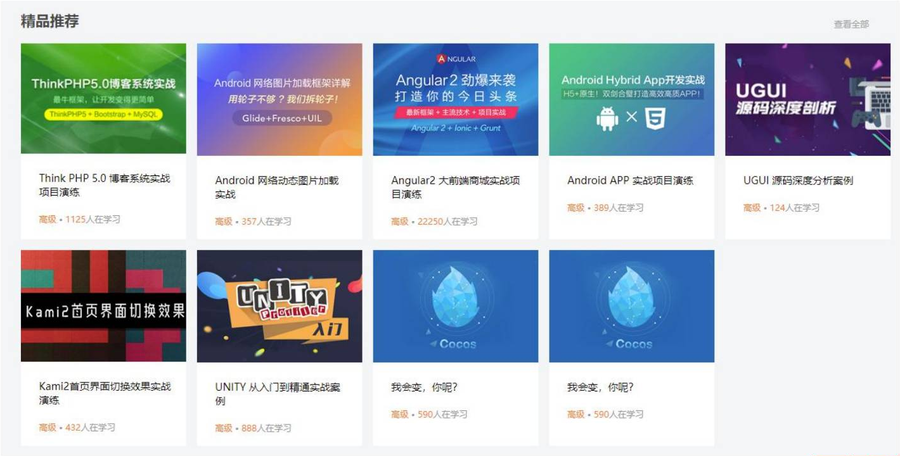

操作文件是 `11-学成在线重构/index.html`。保留其配套 `css/style.css` 和 `images` 目录，从空 `ul` 开始：

```html
    <!-- 4. box核心内容区域开始 -->
    <div class="box w">
        <div class="box-hd">
            <h3>精品推荐</h3>
            <a href="#">查看全部</a>
        </div>
        <div class="box-bd">
            <ul class="clearfix">

            </ul>
        </div>
    </div>
```

公开副本原脚本：

```javascript
        // 1. 重构  
        let data = [
            {
                src: 'images/course01.png',
                title: 'Think PHP 5.0 博客系统实战项目演练',
                num: 1125
            },
            {
                src: 'images/course02.png',
                title: 'Android 网络动态图片加载实战',
                num: 357
            },
            {
                src: 'images/course03.png',
                title: 'Angular2 大前端商城实战项目演练',
                num: 22250
            },
            {
                src: 'images/course04.png',
                title: 'Android APP 实战项目演练',
                num: 389
            },
            {
                src: 'images/course05.png',
                title: 'UGUI 源码深度分析案例',
                num: 124
            },
            {
                src: 'images/course06.png',
                title: 'Kami2首页界面切换效果实战演练',
                num: 432
            },
            {
                src: 'images/course07.png',
                title: 'UNITY 从入门到精通实战案例',
                num: 888
            },
            {
                src: 'images/course08.png',
                title: 'Cocos 深度学习你不会错过的实战',
                num: 590
            },
        ]

        const ul = document.querySelector('.box-bd ul')
        // 2. 根据数据的个数，创建 对应的小li
        for (let i = 0; i < data.length; i++) {
            const li = document.createElement('li')
            // 3. 把内容给每个 li
            li.innerHTML = `
                <a href="#">
                    <img src=${data[i].src} alt="">
                    <h4>
                        ${data[i].title}
                    </h4>
                    <div class="info">
                        <span>高级</span> • <span>${data[i].num}</span>人在学习
                    </div>
                </a>
            `
            // ul 追加 li
            ul.appendChild(li)
        }
    
```

每个对象对应一门课：`src` 是图片路径，`title` 是标题，`num` 是学习人数。遍历过程中创建 `li`，用模板字符串填入卡片内容，再调用 `ul.appendChild(li)`。

打开页面应根据 `data.length` 生成课程卡片。讲义截图显示九张卡片，公开副本数组只有八个对象，因此这个副本会显示八张；数量差异来自数据，不能凭截图补造第九个对象。

### 2.7 克隆节点

需要复制已有结构时，使用 `元素.cloneNode(布尔值)`：传 `true` 为深克隆，复制元素及其所有后代节点；传 `false` 或省略参数为浅克隆，只复制元素本身。复制结果也需要插入页面。

`11-克隆节点.html` 公开副本完整原代码：

```html
<!DOCTYPE html>
<html lang="zh-CN">

<head>
  <meta charset="UTF-8">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>

<body>
  <ul>
    <li>1</li>
    <li>2</li>
    <li>3</li>
  </ul>

  <script>
    const ul = document.querySelector('ul')
    // 1. 选中要克隆的节点
    // 2. 克隆节点
    // cloneNode(true) 深克隆 克隆节点以及节点的所有子节点
    // cloneNode(false) 浅克隆 克隆节点 不克隆子节点
    const liClone = ul.children[0].cloneNode(true)
    // 3. 追加节点
    ul.appendChild(liClone)
    // ul.appendChild(ul.children[0].cloneNode(true))

    // document.body.appendChild(ul.cloneNode(false))
  </script>
</body>

</html>
```

原列表为 `1、2、3`，深克隆第一个 `li` 并追加后变为 `1、2、3、1`。文字也是子节点，改成浅克隆后不会复制 `1` 这段文字。

### 2.8 删除节点与隐藏元素

本课采用 `父元素.removeChild(要删除的子元素)` 删除节点。要删除的节点必须是该父元素的直接子节点。

`12-删除节点.html` 公开副本完整原代码：

```html
<!DOCTYPE html>
<html lang="zh-CN">

<head>
  <meta charset="UTF-8">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>

<body>
  <ul>
    <li>没用了</li>
    <li>123</li>
  </ul>
  <script>
    const ul = document.querySelector('ul')
    // 要删除节点必须用过父元素操作
    // display:none 隐藏元素 但是元素还在文档流中
    // 删除节点后元素会从文档流中移除
    // ul.children[0].style.display = 'none'
    ul.removeChild(ul.children[0])
  </script>
</body>

</html>
```

执行后第一个 `li` 从 DOM 中移除，只剩内容为 `123` 的列表项。

> 原注释把 `display: none` 写成“元素还在文档流中”，这句不准确。应区分 DOM 与布局：`display: none` 保留 DOM 节点，但不占布局空间；`removeChild` 则让节点脱离 DOM。上面的原注释保留，解释以此处为准。

## 3. M 端事件

M 端指移动端。触屏操作需要处理触摸开始、滑动和结束。本节先观察基础事件，后面用插件完成轮播。

### 3.1 触摸开始、移动和结束

讲义介绍 `Touch` 触点对象，代表手指或触控笔等触点，并以 Android、iOS 的触屏交互说明应用场景。

| 事件 | 触发时机 |
| --- | --- |
| `touchstart` | 触摸到 DOM 元素时 |
| `touchmove` | 触点在屏幕上移动时 |
| `touchend` | 触摸结束，手指离开时 |

`13-mobile端事件.html` 公开副本完整原代码：

```html
<!DOCTYPE html>
<html lang="zh-CN">

<head>
  <meta charset="UTF-8">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
  <style>
    div {
      width: 300px;
      height: 300px;
      background-color: pink;
    }
  </style>
</head>

<body>
  <div></div>
  <script>
    const div = document.querySelector('div')
    // 1. 触摸
    div.addEventListener('touchstart', function () {
      console.log('触摸开始')
    })
    // 2. 移动
    div.addEventListener('touchmove', function () {
      console.log('触摸移动')
    })
    // 3. 离开
    div.addEventListener('touchend', function () {
      console.log('触摸结束')
    })
  </script>
</body>

</html>
```

在带触摸的设备上，或浏览器的触摸模拟模式中操作粉色盒子：按下输出“触摸开始”，滑动时输出“触摸移动”，抬起输出“触摸结束”。移动过程中可能触发多次 `touchmove`；普通桌面鼠标点击不等于触摸事件。

## 4. JavaScript 插件

插件是别人已经编写好的代码，用于实现特定效果。课程使用 Swiper 实现移动端轮播，不在这一节手写完整的拖动和切换逻辑。

### 4.1 找到示例、引入文件并修改配置

讲义给出的入口：

- [Swiper 中文网站](https://www.swiper.com.cn/)
- [演示效果](https://www.swiper.com.cn/demo/index.html)
- [使用方法](https://www.swiper.com.cn/usage/index.html)
- [API 参数](https://www.swiper.com.cn/api/index.html)

按课程流程使用：

1. 在演示页找到需要的效果，查看相应结构和初始化代码。
2. 下载源码，从讲义所示的 `package` 目录取得 CSS 与 JS 文件，放到项目对应目录。
3. 在 HTML 中引入 CSS，编写轮播容器、包裹层、每一张幻灯片和分页器。
4. 在初始化前引入 JS，再调用 `new Swiper(选择器, 配置对象)`。
5. 根据 API 调整自动播放、分页器等参数，检查效果。

一个页面有多个轮播时，需要区分容器类名和分页器的作用范围，避免几个实例使用同一个选择器。课程副本附带的是 Swiper `5.4.5`，使用网页文档时也要核对版本对应的类名和参数。

### 4.2 基础轮播：自动播放、分页器与键盘

操作文件是 `14-移动端轮播图.html`，配套文件为 `css/swiper.min.css` 和 `js/swiper.min.js`。公开副本完整原代码：

```html
<!DOCTYPE html>
<html lang="en">

<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
  <link rel="stylesheet" href="./css/swiper.min.css">
  <style>
    .box {
      position: relative;
      width: 800px;
      height: 300px;
      background-color: pink;
      margin: 100px auto;
    }

    html,
    body {
      position: relative;
      height: 100%;
    }

    body {
      background: #eee;
      font-family: Helvetica Neue, Helvetica, Arial, sans-serif;
      font-size: 14px;
      color: #000;
      margin: 0;
      padding: 0;
    }

    .swiper {
      overflow: hidden;
      width: 100%;
      height: 100%;
    }

    .swiper-slide {
      text-align: center;
      font-size: 18px;
      background: #fff;

      /* Center slide text vertically */
      display: -webkit-box;
      display: -ms-flexbox;
      display: -webkit-flex;
      display: flex;
      -webkit-box-pack: center;
      -ms-flex-pack: center;
      -webkit-justify-content: center;
      justify-content: center;
      -webkit-box-align: center;
      -ms-flex-align: center;
      -webkit-align-items: center;
      align-items: center;
    }

    .swiper-slide img {
      display: block;
      width: 100%;
      height: 100%;
      object-fit: cover;
    }
  </style>

</head>

<body>
  <div class="box">
    <!-- Swiper -->
    <div class="swiper mySwiper">
      <div class="swiper-wrapper">
        <div class="swiper-slide">Slide 1</div>
        <div class="swiper-slide">Slide 2</div>
        <div class="swiper-slide">Slide 3</div>
        <div class="swiper-slide">Slide 4</div>
        <div class="swiper-slide">Slide 5</div>
        <div class="swiper-slide">Slide 6</div>
        <div class="swiper-slide">Slide 7</div>
        <div class="swiper-slide">Slide 8</div>
        <div class="swiper-slide">Slide 9</div>
      </div>
      <div class="swiper-pagination"></div>
    </div>


  </div>
  <script src="./js/swiper.min.js"></script>
  <script>
    var swiper = new Swiper(".mySwiper", {
      // 小圆点
      pagination: {
        el: ".swiper-pagination",
      },
      // 自动播放
      autoplay: {
        delay: 1000,//1秒切换一次
        disableOnInteraction: false,  // 鼠标点击 触摸之后，自动继续播放
      },
      // 可以键盘控制
      keyboard: {
        enabled: true,
        onlyInViewport: true,
      },
    });
  </script>
</body>

</html>
```

| 代码位置 | 作用 |
| --- | --- |
| `.mySwiper` | 初始化的目标容器 |
| `.swiper-wrapper` | 包裹所有幻灯片 |
| `.swiper-slide` | 一张幻灯片，副本共九张 |
| `pagination.el` | 指定小圆点所在的分页器 |
| `autoplay.delay: 1000` | 每隔一秒自动切换 |
| `disableOnInteraction: false` | 用户操作后继续自动播放 |
| `keyboard.enabled: true` | 启用键盘控制 |
| `onlyInViewport: true` | 轮播位于视口内时响应键盘 |

打开页面可观察当前页和九个小圆点随自动播放变化，按方向键可切换。分页器没有配置 `clickable: true`，不能把“点击小圆点跳转”当成本例已经启用的功能。

原容器类名是 `.swiper`，配套 Swiper 5 的默认容器样式使用 `.swiper-container`。本例另外写了宽、高、裁切样式，实测能自动切换；但 `.mySwiper` 的定位仍为 `static`，分页器参照外面的 `.box` 定位。若复用时需要完整默认容器样式，可**局部修正**为下面的类名，保留 `.mySwiper` 供初始化选择；修改后轮播容器自身为 `position: relative`：

```html
<div class="swiper-container swiper mySwiper">
```

## 5. 综合案例

本课依次完成游乐园轮播图和学生信息表。前者练习把插件接入既有页面，后者练习用数组驱动页面的新增和删除。

### 5.1 游乐园：把静态 banner 接入 Swiper

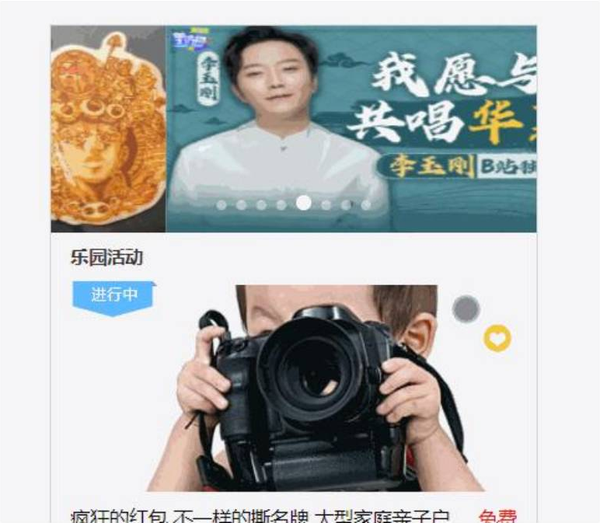

操作公开副本的 `FC/index.html`，保留 `css`、`js`、`uploads` 和 `lib` 等配套目录。原页面引入 `css/index.css` 和 `css/swiper.min.css`；页面的移动端布局由配套样式与 `flexible.js` 提供。

下面摘录原轮播 HTML，省略与本日轮播逻辑无关的重复活动列表和页脚：

```html
    <!-- 轮播图模块 -->
    <div class="banner">
      <!-- 轮播图模块 -->
      <!-- Swiper -->
      <div class="swiper-container">
        <div class="swiper-wrapper">
          <div class="swiper-slide">
            <a href="#"><img src="./uploads/banner_1.png" alt=""></a>
          </div>
          <div class="swiper-slide">
            <a href="#"><img src="./uploads/banner_1.png" alt=""></a>
          </div>
          <div class="swiper-slide">
            <a href="#"><img src="./uploads/banner_1.png" alt=""></a>
          </div>
          <div class="swiper-slide">
            <a href="#"><img src="./uploads/banner_1.png" alt=""></a>
          </div>
          <div class="swiper-slide">
            <a href="#"><img src="./uploads/banner_1.png" alt=""></a>
          </div>
        </div>
        <!-- Add Pagination -->
        <div class="swiper-pagination"></div>
      </div>
    </div>
```

原页面内的 Swiper 样式：

```css
    html,
    body {
      position: relative;
      height: 100%;
    }

    body {
      background: #eee;
      font-family: Helvetica Neue, Helvetica, Arial, sans-serif;
      font-size: 14px;
      color: #000;
      margin: 0;
      padding: 0;
    }

    .swiper-container {
      width: 100%;
      height: 100%;
    }

    .swiper-slide {
      text-align: center;
      font-size: 18px;
      background: #fff;

      /* Center slide text vertically */
      display: -webkit-box;
      display: -ms-flexbox;
      display: -webkit-flex;
      display: flex;
      -webkit-box-pack: center;
      -ms-flex-pack: center;
      -webkit-justify-content: center;
      justify-content: center;
      -webkit-box-align: center;
      -ms-flex-align: center;
      -webkit-align-items: center;
      align-items: center;
    }

    .swiper-pagination-bullet {
      background: #fff;
      opacity: .8;
    }

    .swiper-pagination-bullet-active {
      background: pink;
    }
  
```

页面底部原引入代码，顺序在初始化之前：

```html
  <!-- 引入js文件 -->
  <script src="./js/flexible.js"></script>
  <script src="./js/swiper.min.js"></script>
```

公开副本原初始化脚本：

```javascript
    var swiper = new Swiper('.swiper-container', {
      pagination: {
        // 分页器 小圆点
        el: '.swiper-pagination',
      },
      autoplay: {
        delay: 3000,//3秒切换一次
      },
    });
  
```

现在 banner 中有五张幻灯片，每三秒切换，小圆点用白色，当前页为粉色。副本五张都引用同一张 `banner_1.png`，切换索引时图片内容不变，应观察圆点或实际滑动过程来确认轮播，不能据此认定未运行。

此例没有设置 `disableOnInteraction: false`；按配套版本的默认行为，用户拖动后自动播放会停止。若要求操作后继续自动播放，可参照上一节配置，需明确这是新增参数。

### 5.2 学生信息表：先明确数据与业务

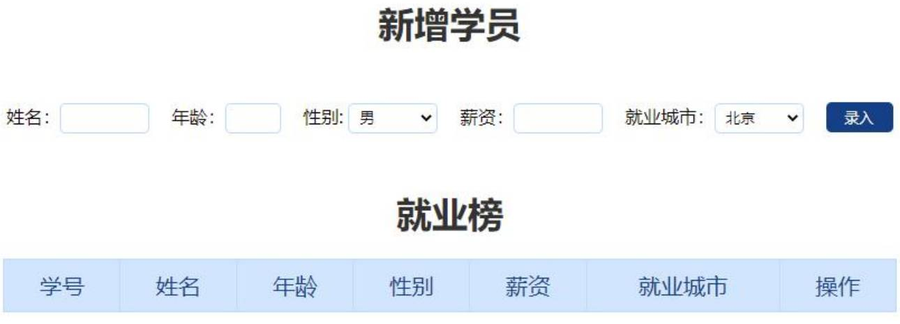

学生信息表有两个主要业务：录入学员、删除学员。讲义强调先操作数组，再根据数组渲染，避免每个业务都单独修改大量 DOM。

学习流程是：空数组 → 收集一名学生的数据对象 → `push` 到数组 → 渲染表格；删除时找到对应数组项 → `splice` → 重新渲染。

讲义展示的对象格式如下，属于**讲义转录**，用于说明字段，并非要求页面加载时插入这条数据：

```javascript
const initData = [
  {
    stuId: 1001,
    uname: '欧阳霸天',
    age: 19,
    gender: '男',
    salary: '20000',
    city: '上海',
  }
]
```

实际练习从 `const arr = []` 开始。`stuId` 为显示的学号，姓名、年龄、性别、薪资、城市分别来自各表单元素的 `.value`。

### 5.3 录入与渲染：对象入数组，数组变表格

在 `学生信息表/学生信息表案例.html` 中按以下顺序理解：

1. 获取表单元素和 `tbody`，声明空数组 `arr`。
2. 监听表单的 `submit`，先用 `e.preventDefault()` 阻止默认提交和页面跳转。
3. 从每个表单元素的 `.value` 收集数据，组成学生对象。
4. `arr.push(obj)` 保存数据，再调用 `render()` 显示。
5. 重置表单，让下一次录入从空输入框开始。

`render()` 先清空 `tbody.innerHTML`，再遍历数组，每条数据创建一个 `tr`，把七个单元格填进去并追加到 `tbody`。如果不先清空，每次渲染会在旧行后重复追加。

讲义步骤写先渲染后重置，公开副本先 `this.reset()` 后 `render()`。对象已经收集并放入数组，`render()` 读取数组，因此本例两种顺序都能显示这次录入的数据。表单重置会恢复控件的默认值，性别和城市选择框也回到默认选项。

### 5.4 删除：索引写入链接，事件委托给 tbody

每次渲染时，删除链接写入 `data-id="${i}"`，保存该行当前对应的数组索引。索引从 `0` 开始，它与学号 `stuId` 是不同的字段。

把点击事件委托给 `tbody`，只在 `e.target.tagName === 'A'` 时执行删除。使用 `e.target.dataset.id` 找到数组位置，再 `arr.splice(索引, 1)` 删除一项，最后重新渲染。

删除后剩余数组项的索引会变化，重新渲染也会生成新的 `data-id`，让链接继续对应正确的数据。只从页面移除 `tr` 而不改数组，会在下一次渲染时让那条数据再次出现。

### 5.5 表单验证的位置

讲义要求通过共同的 `name` 属性获取需要填写的表单控件，遍历它们。如果某个 `.value === ''`，用 `return alert(...)` 提示并结束本次事件处理。

验证应放在 `e.preventDefault()` 之后、收集并新增数据之前。这样既阻止了默认提交，也不会把缺少信息的对象推入数组。

这次课程只判断空字符串，没有检查全空格、年龄或薪资是否为有效数字。原表单使用文本输入框，`.value` 得到的是字符串；不要把本例的非空检查理解成完整的数字校验。

### 5.6 学生信息表完整原代码与操作检查

下面是公开副本的完整 `学生信息表案例.html`，配套样式为同目录的 `css/index.css`：

```html
<!DOCTYPE html>
<html lang="en">

<head>
  <meta charset="UTF-8" />
  <meta name="viewport" content="width=device-width, initial-scale=1.0" />
  <meta http-equiv="X-UA-Compatible" content="ie=edge" />
  <title>学生信息管理</title>
  <link rel="stylesheet" href="css/index.css" />
</head>

<body>
  <h1>新增学员</h1>
  <form class="info" autocomplete="off">
    <!-- 只有设置了 name 属性的表单元素才能在提交表单时传递它们的值 -->
    姓名：<input type="text" class="uname" name="uname" />
    年龄：<input type="text" class="age" name="age" />
    性别:
    <select name="gender" class="gender">
      <option value="男">男</option>
      <option value="女">女</option>
    </select>
    薪资：<input type="text" class="salary" name="salary" />
    就业城市：<select name="city" class="city">
      <option value="北京">北京</option>
      <option value="上海">上海</option>
      <option value="广州">广州</option>
      <option value="深圳">深圳</option>
      <option value="曹县">曹县</option>
    </select>
    <button class="add">录入</button>
  </form>

  <h1>就业榜</h1>
  <table>
    <thead>
      <tr>
        <th>学号</th>
        <th>姓名</th>
        <th>年龄</th>
        <th>性别</th>
        <th>薪资</th>
        <th>就业城市</th>
        <th>操作</th>
      </tr>
    </thead>
    <tbody>
      <!-- 
        <tr>
          <td>1001</td>
          <td>欧阳霸天</td>
          <td>19</td>
          <td>男</td>
          <td>15000</td>
          <td>上海</td>
          <td>
            <a href="javascript:">删除</a>
          </td>
        </tr> 
        -->
    </tbody>
  </table>
  <script>
    // 获取元素
    const uname = document.querySelector('.uname')
    const age = document.querySelector('.age')
    const gender = document.querySelector('.gender')
    const salary = document.querySelector('.salary')
    const city = document.querySelector('.city')
    const tbody = document.querySelector('tbody')
    // 获取所有带有 name 属性的表单元素
    const inputs = document.querySelectorAll('[name]')
    // 声明一个空数组，所有增删改查操作都是hi针对这个数组
    const arr = []
    // 1. 录入模块
    // 1.1 表单提交事件
    const info = document.querySelector('.info')

    info.addEventListener('submit', function (e) {
      // 1.1.1 阻止表单默认提交
      e.preventDefault()
      // 表单验证 若不通过 则不执行后续代码
      for (let i = 0; i < inputs.length; i++) {
        if (inputs[i].value === '') {
          return alert('请填写完整信息')
        }
      }
      // 1.1.2 收集表单数据
      const obj = {
        // 元素.value 不是 name.value
        stuId: arr.length + 1,
        uname: uname.value,
        age: age.value,
        gender: gender.value,
        salary: salary.value,
        city: city.value,
      }
      // 1.1.3 把对象添加到数组中
      arr.push(obj)
      // console.log(arr)
      // 1.1.4 清空表单
      this.reset()
      // 1.1.5 渲染到页面
      render()
    })

    // 2. 渲染模块
    function render() {
      // 1.1 清空 tbody 内容
      tbody.innerHTML = ''
      // 1.2 遍历数组，创建 tr 追加到 tbody 中
      for (let i = 0; i < arr.length; i++) {
        const tr = document.createElement('tr')
        tr.innerHTML = `
          <td>${arr[i].stuId}</td>
          <td>${arr[i].uname}</td>
          <td>${arr[i].age}</td>
          <td>${arr[i].gender}</td>
          <td>${arr[i].salary}</td>
          <td>${arr[i].city}</td>
          <td>
            <a href="javascript:" data-id="${i}">删除</a>
          </td>
        `
        tbody.appendChild(tr)
      }
    }

    // 3. 删除模块
    // 3.1 点击删除事件
    // 事件委托给 tbody
    tbody.addEventListener('click', function (e) {
      // 3.1.1 判断是否点击了删除
      if (e.target.tagName === 'A') {
        // 3.1.2 删除数组中对应的元素 通过自定义属性 data-id
        arr.splice(e.target.dataset.id, 1)
        // 3.1.3 重新渲染页面
        render()
      }
    })
  </script>

</body>

</html>
```

打开页面后按以下顺序检查：

1. 不填写姓名、年龄、薪资直接录入，应提示“请填写完整信息”，表格保持为空。
2. 填写完整资料后录入，应新增一行，表单恢复默认值。
3. 连续录入第二名学员，应有两行，原有行不能重复。
4. 点击某行“删除”，该条数组数据移除，其他行仍显示；继续删除直到表格为空。

> 原例用 `arr.length + 1` 生成学号，删除后新增会产生重复。例如已有学号 `1、2`，删除 `1` 后数组长度为 `1`，下次新增又得到 `2`。这与 `data-id` 索引重排是两个问题。

如果只修正当前页面会话内的学号重复，可在 `arr` 定义之后增加独立计数变量，并替换对象中的 `stuId` 字段，属于**局部修正**：

```javascript
let nextStuId = 1
```

```javascript
stuId: nextStuId++,
```

第二段是对象字段，不是单独执行的语句。计数只在通过验证、创建对象时递增；删除不退回计数。修改后录入 `1、2`，删除 `1` 再新增，应得到 `2、3`。

本例把输入值拼进 `innerHTML`，输入标签会被当作 HTML 解析，不能用它直接呈现任意的纯文本输入。数组也只在当前页面内存中，刷新后数据丢失；本地存储是讲义安排的下一课内容，本篇不提前实现。

## 6. 重绘和回流

学生表中的增加和删除会改变可见页面结构。讲义接着说明浏览器如何把 DOM 和样式变成画面，以及这些操作为何可能触发布局与绘制。

### 6.1 浏览器的渲染过程

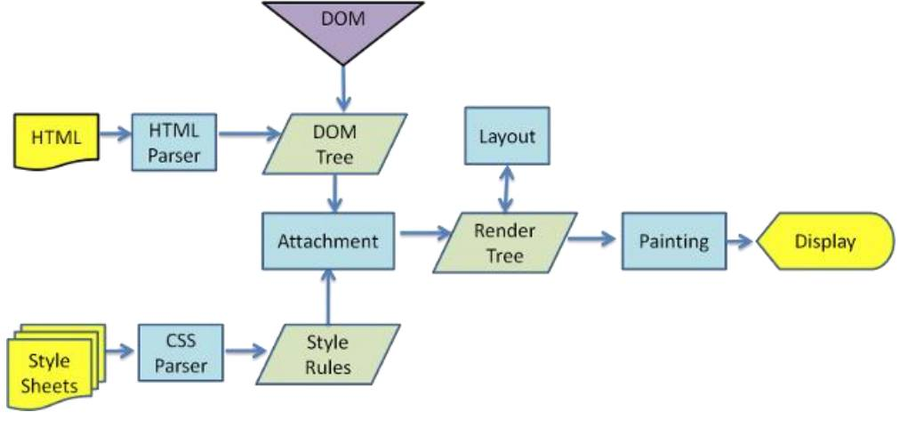

按原图的简化流程：

1. 解析 HTML，生成 DOM 树。
2. 解析 CSS，生成样式规则。
3. 根据 DOM 和样式规则，生成渲染树。
4. 执行布局 `Layout`，计算节点的尺寸、位置等几何信息。
5. 执行绘制 `Painting`，根据计算结果绘制页面。
6. 显示 `Display`，呈现画面。

### 6.2 回流与重绘的区别

**回流，也叫重排**：元素的尺寸、结构或布局改变，浏览器需要重新计算部分或全部元素的几何信息。

**重绘**：外观发生变化，但不影响位置和布局，例如改变 `color`、`background-color` 或 `outline`。

按本课的简化渲染模型，重绘不一定引起回流，回流会进一步引起重绘。判断某次变化时，先问它是否改变了布局。

讲义列举可能引发回流的操作：页面首次刷新、窗口大小改变、元素尺寸或位置改变、字体大小改变、影响布局的内容变化、激活改变布局的 CSS 伪类，以及增加或删除可见 DOM 元素。

`:hover` 或输入行为本身不一定回流；如果只改颜色、或输入并未改变元素几何信息，就不能仅凭行为名称认定产生回流。关键仍是布局有没有变化。

### 6.3 结合样式代码判断影响

以下为**讲义第 52 页代码图转录**：

```javascript
let s = document.body.style
s.padding = "2px" // 重排 + 重绘
s.border = "1px solid red" // 再次 重排 + 重绘
s.color = "blue" // 再次重绘
s.backgroundColor = "#ccc" // 再次 重绘
s.fontSize = "14px" // 再一次 重排 + 重绘
```

内边距、边框、字号会影响尺寸或排布；文字颜色和背景颜色只改变外观。这段用于学习操作类型，浏览器可能批量处理连续的样式写入，不能据注释断言每一行都立刻发生一次独立布局或绘制。

## 7. 今日作业与预习

讲义第 53 页安排：

1. 整理今天笔记。
2. 练习学成在线渲染、倒计时和微博发布案例。
3. 做测试题。
4. 完成配套作业。
5. 预习下一课的本地存储。

学成在线按数据生成卡片；倒计时重点检查时间戳差值、秒数拆分、补零和到期处理。微博发布在讲义中用于说明“创建 → 填写内容 → 插入”的节点操作，并列为作业练习；本篇保留这项任务，不把未取得的原作业实现补成已读原文。

另已核实网盘 `07-作业` 的实际目录清单：

| 作业目录 | HTML 文件 |
| --- | --- |
| `创建英雄列表` | `hero(学生练习).html`、`hero(老师参考).html`，另有 `css`、`js`、`uploads` |
| `网页时钟` | `网页时钟（图形版）.html`，另有 `images` |

原 Markdown 的普通下载要求登录，配套测试题与作业正文尚未取得。本节记录讲义任务和已读取的目录清单，不据文件名编写原作业答案。练习学生信息表时，另留意验证位置、渲染前清空、删除时更新数组和索引与学号的区别。